# Lab Mid - Ablation Study of Regularization Techniques in a Multilayer Perceptron Using the Iris Dataset

**Name:** Eman Amjad
**Roll Number:** FA23-BAI-013
**Course:** Artificial Neural Networks

---

A Multilayer Perceptron (MLP) classifies iris flowers into *Setosa*, *Versicolor* and *Virginica*.
Starting from a baseline, one training choice is changed at a time - weight initialization, L2
regularization, dropout and learning rate - and the effect on accuracy, macro F1, test loss,
generalization and training duration is measured. Every experiment uses the same data split,
the same architecture and the same early-stopping policy, and is repeated with three random seeds.

### Contents

1. Setup and configuration
2. Data loading, stratified 60/20/20 split and leakage-free standardization
3. Model definition (fixed architecture)
4. Reproducing the overfitting scenario (baseline without early stopping)
5. Ablation experiments E0-E6 with early stopping (3 seeds each)
6. Results tables
7. Learning curves
8. Metric comparison plots
9. Best configuration: confusion matrix and classification report
10. Discussion and conclusion

---

## 1. Setup and Configuration

All constants that must stay fixed across experiments are defined once here: the split seed, the
three model seeds, the epoch budget, the early-stopping patience and the batch size.
`enable_op_determinism()` makes TensorFlow produce identical results for an identical seed, so each
run in this notebook can be reproduced exactly.

In [1]:
# Eman Amjad | FA23-BAI-013
# Artificial Neural Networks - Lab Mid - Ablation study of regularization in an MLP (Iris)

import os
import time
import json
import warnings

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf
import keras
from keras import layers, regularizers, initializers

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, log_loss,
                             confusion_matrix, classification_report)

tf.config.experimental.enable_op_determinism()
tf.get_logger().setLevel("ERROR")

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Colours for the plots (train vs validation, and the single bar colour)
C_TRAIN, C_VAL, C_BAR, C_REF = "#2a78d6", "#eb6834", "#2a78d6", "#52514e"

SPLIT_SEED = 13                # fixed data split for every experiment (roll number 013)
SEEDS      = [13, 113, 213]    # three model seeds: initialization, dropout masks, batch order
MAX_EPOCHS = 200
PATIENCE   = 15
BATCH_SIZE = 16
FIG_DIR    = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

print("TensorFlow  :", tf.__version__)
print("Keras       :", keras.__version__)
print("scikit-learn:", sklearn.__version__)
print("NumPy       :", np.__version__)
print(f"Split seed = {SPLIT_SEED}, model seeds = {SEEDS}, "
      f"max epochs = {MAX_EPOCHS}, patience = {PATIENCE}, batch size = {BATCH_SIZE}")

TensorFlow  : 2.21.0
Keras       : 3.15.1
scikit-learn: 1.9.1
NumPy       : 2.5.3
Split seed = 13, model seeds = [13, 113, 213], max epochs = 200, patience = 15, batch size = 16


---

## 2. Data Loading, Stratified Split and Standardization

The 150 samples are split **60% / 20% / 20%** into **90 / 30 / 30** samples. A stratified split
keeps each class at exactly one third of every subset. The split is made in two steps: 30 test
samples are held out first, then 30 validation samples are taken from the remaining 120.

The `StandardScaler` is **fitted on the training set only** and that same scaler transforms the
validation and test sets, so no statistic of the validation or test data leaks into training.

In [2]:
# Eman Amjad | FA23-BAI-013 | Data loading and split
iris = load_iris()
X, y = iris.data, iris.target
CLASS_NAMES = [str(c) for c in iris.target_names]

print("Feature matrix:", X.shape, "| labels:", y.shape)
print("Features      :", iris.feature_names)
print("Classes       :", CLASS_NAMES)

# Step 1: hold out 30 test samples; step 2: 30 validation samples from the remaining 120.
X_trval, X_test, y_trval, y_test = train_test_split(
    X, y, test_size=30, stratify=y, random_state=SPLIT_SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_trval, y_trval, test_size=30, stratify=y_trval, random_state=SPLIT_SEED)

split_table = pd.DataFrame({
    name: np.bincount(labels, minlength=3)
    for name, labels in [("train", y_train), ("validation", y_val), ("test", y_test)]
}, index=CLASS_NAMES).T
split_table["total"] = split_table.sum(axis=1)
split_table["share"] = (split_table["total"] / len(y)).map("{:.0%}".format)
split_table

Feature matrix: (150, 4) | labels: (150,)
Features      : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes       : ['setosa', 'versicolor', 'virginica']


,setosa,versicolor,virginica,total,share
train,30,30,30,90,60%
validation,10,10,10,30,20%
test,10,10,10,30,20%


In [3]:
# Eman Amjad | FA23-BAI-013 | Leakage-free standardization
scaler = StandardScaler().fit(X_train)          # statistics from the training set ONLY
X_train_s = scaler.transform(X_train)
X_val_s   = scaler.transform(X_val)             # same scaler re-used, never re-fitted
X_test_s  = scaler.transform(X_test)

check = pd.DataFrame({
    "train mean": X_train_s.mean(0), "train std": X_train_s.std(0),
    "val mean":   X_val_s.mean(0),   "test mean": X_test_s.mean(0),
}, index=iris.feature_names).round(3)
print("Training features are exactly mean 0 / std 1; validation and test are close but not")
print("exactly 0, which confirms the scaler never saw them.\n")
check

Training features are exactly mean 0 / std 1; validation and test are close but not
exactly 0, which confirms the scaler never saw them.



,train mean,train std,val mean,test mean
sepal length (cm),0.0,1.0,0.135,0.187
sepal width (cm),-0.0,1.0,-0.102,0.135
petal length (cm),0.0,1.0,0.010,0.042
petal width (cm),-0.0,1.0,-0.099,0.037


---

## 3. Model Definition (Fixed Architecture)

| Layer | Units | Activation | Regularization |
|---|---|---|---|
| Input | 4 | - | - |
| Dense (hidden 1) | 64 | ReLU | L2 on kernel (λ) |
| Dropout | - | - | rate *p* |
| Dense (hidden 2) | 32 | ReLU | L2 on kernel (λ) |
| Dropout | - | - | rate *p* |
| Dense (output) | 3 | Softmax | L2 on kernel (λ) |

* **Optimizer:** Adam with the experiment's learning rate. **Loss:** sparse categorical cross-entropy.
* The Dropout layers are always present; with *p* = 0.0 they pass the input through unchanged, so
  the architecture (and the parameter count) is identical in every experiment.
* `keras.utils.set_random_seed(seed)` plus an explicit seed on each initializer and dropout layer
  makes a run fully determined by its seed.

In [4]:
# Eman Amjad | FA23-BAI-013 | Model builder
INITIALIZERS = {
    "Glorot uniform": initializers.GlorotUniform,
    "He normal":      initializers.HeNormal,
}

def build_model(init, l2, dropout, lr, seed):
    """Fixed 4-64-32-3 MLP; only init, L2, dropout and learning rate vary."""
    keras.utils.set_random_seed(seed)
    make_init = INITIALIZERS[init]
    reg = (lambda: regularizers.L2(l2)) if l2 > 0 else (lambda: None)

    model = keras.Sequential([
        keras.Input(shape=(4,)),
        layers.Dense(64, activation="relu", kernel_initializer=make_init(seed=seed),
                     kernel_regularizer=reg(), name="hidden_1"),
        layers.Dropout(dropout, seed=seed, name="dropout_1"),
        layers.Dense(32, activation="relu", kernel_initializer=make_init(seed=seed + 1),
                     kernel_regularizer=reg(), name="hidden_2"),
        layers.Dropout(dropout, seed=seed + 1, name="dropout_2"),
        layers.Dense(3, activation="softmax", kernel_initializer=make_init(seed=seed + 2),
                     kernel_regularizer=reg(), name="output"),
    ], name="iris_mlp")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss=keras.losses.SparseCategoricalCrossentropy(),
                  metrics=["accuracy"])
    return model

build_model("Glorot uniform", 0.0, 0.0, 1e-3, SEEDS[0]).summary()

Model: "iris_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 64)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,499 (9.76 KB)

 Trainable params: 2,499 (9.76 KB)

 Non-trainable params: 0 (0.00 B)

---

## 4. Reproducing the Overfitting Scenario

The lab describes preliminary runs where training accuracy is high but **validation loss starts to
rise while training loss keeps falling**. To see this directly, the baseline (E0) is trained for the
full 200 epochs **without** early stopping. The epoch with the lowest validation loss is marked; that
is the point early stopping (patience 15, restore best weights) would return.

Lowest validation loss : 0.1454 at epoch 62
Validation loss at 200 : 0.3393  (+0.1938 above its minimum)
Training loss at  62  : 0.0416
Training loss at 200 : 0.0061  (still falling)
Training accuracy at 200 : 1.000 | validation accuracy at 200 : 0.867
Early stopping (patience 15) would stop at epoch 77 and restore the weights of epoch 62.


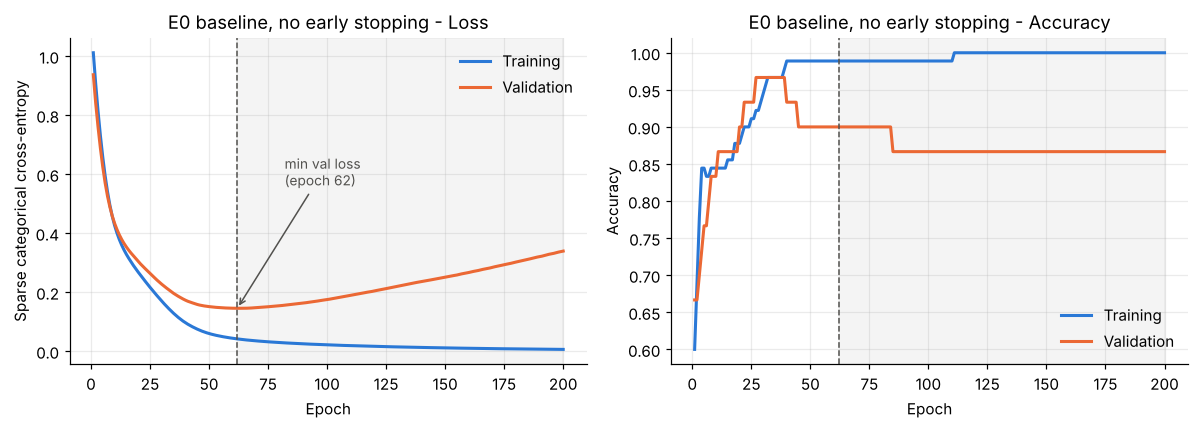

In [5]:
# Eman Amjad | FA23-BAI-013 | Baseline for 200 epochs without early stopping
demo = build_model("Glorot uniform", 0.0, 0.0, 1e-3, SEEDS[0])
demo_hist = demo.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                     epochs=MAX_EPOCHS, batch_size=BATCH_SIZE, verbose=0).history

ep = np.arange(1, MAX_EPOCHS + 1)
best_ep = int(np.argmin(demo_hist["val_loss"])) + 1
es_stop = min(best_ep + PATIENCE, MAX_EPOCHS)

print(f"Lowest validation loss : {min(demo_hist['val_loss']):.4f} at epoch {best_ep}")
print(f"Validation loss at 200 : {demo_hist['val_loss'][-1]:.4f}  "
      f"(+{demo_hist['val_loss'][-1] - min(demo_hist['val_loss']):.4f} above its minimum)")
print(f"Training loss at {best_ep:>3}  : {demo_hist['loss'][best_ep - 1]:.4f}")
print(f"Training loss at 200 : {demo_hist['loss'][-1]:.4f}  (still falling)")
print(f"Training accuracy at 200 : {demo_hist['accuracy'][-1]:.3f} | "
      f"validation accuracy at 200 : {demo_hist['val_accuracy'][-1]:.3f}")
print(f"Early stopping (patience {PATIENCE}) would stop at epoch {es_stop} "
      f"and restore the weights of epoch {best_ep}.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, key, title in [(axes[0], "loss", "Loss"), (axes[1], "accuracy", "Accuracy")]:
    ax.plot(ep, demo_hist[key], color=C_TRAIN, lw=2, label="Training")
    ax.plot(ep, demo_hist["val_" + key], color=C_VAL, lw=2, label="Validation")
    ax.axvline(best_ep, color=C_REF, ls="--", lw=1)
    ax.axvspan(best_ep, MAX_EPOCHS, color=C_REF, alpha=0.06)
    ax.set_xlabel("Epoch"); ax.set_title(f"E0 baseline, no early stopping - {title}")
    ax.legend(frameon=False)
axes[0].annotate(f"min val loss\n(epoch {best_ep})", xy=(best_ep, min(demo_hist["val_loss"])),
                 xytext=(best_ep + 20, max(demo_hist["val_loss"]) * 0.6),
                 arrowprops=dict(arrowstyle="->", color=C_REF), color=C_REF, fontsize=9)
axes[0].set_ylabel("Sparse categorical cross-entropy"); axes[1].set_ylabel("Accuracy")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig1_overfitting_baseline.png", dpi=200, bbox_inches="tight")
plt.show()

---

## 5. Ablation Experiments (E0 - E6)

| Experiment | Initialization | L2 | Dropout | Learning rate | Factor tested |
|---|---|---|---|---|---|
| E0: Baseline | Glorot uniform | 0.0 | 0.0 | 0.001 | reference |
| E1: Initialization | He normal | 0.0 | 0.0 | 0.001 | initialization (vs E0) |
| E2: L2 | Glorot uniform | 0.01 | 0.0 | 0.001 | L2 (vs E0) |
| E3: Dropout | Glorot uniform | 0.0 | 0.3 | 0.001 | dropout (vs E0) |
| E4: Combined | Glorot uniform | 0.01 | 0.3 | 0.001 | L2 + dropout (vs E0) |
| E5: Low learning rate | Glorot uniform | 0.01 | 0.3 | 0.0001 | learning rate (vs E4) |
| E6: High learning rate | Glorot uniform | 0.01 | 0.3 | 0.01 | learning rate (vs E4) |

**Early-stopping policy (identical for all runs):** monitor `val_loss`, patience 15,
`restore_best_weights=True`, maximum 200 epochs.

**Metrics recorded per run:** epochs trained, best epoch, training time, train / validation / test
accuracy, **test macro F1**, and **test loss**. The test loss reported is the *pure* cross-entropy
on the test set (`sklearn.metrics.log_loss`), so experiments with and without L2 are compared on the
same footing; Keras' `evaluate()` would add the L2 penalty to the loss, which is also stored
(`test_loss_keras`) for reference.

In [6]:
# Eman Amjad | FA23-BAI-013 | Experiment configuration
EXPERIMENTS = [
    dict(exp="E0", name="Baseline",           init="Glorot uniform", l2=0.0,  dropout=0.0, lr=1e-3),
    dict(exp="E1", name="Initialization",     init="He normal",      l2=0.0,  dropout=0.0, lr=1e-3),
    dict(exp="E2", name="L2",                 init="Glorot uniform", l2=0.01, dropout=0.0, lr=1e-3),
    dict(exp="E3", name="Dropout",            init="Glorot uniform", l2=0.0,  dropout=0.3, lr=1e-3),
    dict(exp="E4", name="Combined",           init="Glorot uniform", l2=0.01, dropout=0.3, lr=1e-3),
    dict(exp="E5", name="Low learning rate",  init="Glorot uniform", l2=0.01, dropout=0.3, lr=1e-4),
    dict(exp="E6", name="High learning rate", init="Glorot uniform", l2=0.01, dropout=0.3, lr=1e-2),
]
pd.DataFrame(EXPERIMENTS).set_index("exp")

,name,init,l2,dropout,lr
exp,,,,,
E0,Baseline,Glorot uniform,0.00,0.0,0.0010
E1,Initialization,He normal,0.00,0.0,0.0010
E2,L2,Glorot uniform,0.01,0.0,0.0010
E3,Dropout,Glorot uniform,0.00,0.3,0.0010
E4,Combined,Glorot uniform,0.01,0.3,0.0010
E5,Low learning rate,Glorot uniform,0.01,0.3,0.0001
E6,High learning rate,Glorot uniform,0.01,0.3,0.0100


In [7]:
# Eman Amjad | FA23-BAI-013 | One training run
def run_experiment(cfg, seed):
    model = build_model(cfg["init"], cfg["l2"], cfg["dropout"], cfg["lr"], seed)
    early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                          restore_best_weights=True)
    t0 = time.perf_counter()
    hist = model.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                     epochs=MAX_EPOCHS, batch_size=BATCH_SIZE,
                     callbacks=[early], verbose=0).history
    train_time = time.perf_counter() - t0

    # The restored (best-epoch) weights are evaluated below.
    p_train = model.predict(X_train_s, verbose=0)
    p_val   = model.predict(X_val_s, verbose=0)
    p_test  = model.predict(X_test_s, verbose=0)
    y_pred  = p_test.argmax(1)
    epochs_run = len(hist["loss"])
    best_epoch = int(np.argmin(hist["val_loss"])) + 1

    row = dict(
        exp=cfg["exp"], name=cfg["name"], seed=seed,
        epochs_run=epochs_run, best_epoch=best_epoch,
        stopped_early=epochs_run < MAX_EPOCHS,
        train_time_s=train_time,
        train_acc=accuracy_score(y_train, p_train.argmax(1)),
        val_acc=accuracy_score(y_val, p_val.argmax(1)),
        best_val_loss=float(min(hist["val_loss"])),     # as monitored (includes any L2 penalty)
        val_ce=log_loss(y_val, p_val, labels=[0, 1, 2]),  # pure cross-entropy, restored weights
        val_loss_rise=float(hist["val_loss"][-1] - min(hist["val_loss"])),
        train_loss=log_loss(y_train, p_train, labels=[0, 1, 2]),
        test_acc=accuracy_score(y_test, y_pred),
        test_f1_macro=f1_score(y_test, y_pred, average="macro"),
        test_loss=log_loss(y_test, p_test, labels=[0, 1, 2]),
        test_loss_keras=float(model.evaluate(X_test_s, y_test, verbose=0)[0]),
    )
    return row, hist, y_pred

In [8]:
# Eman Amjad | FA23-BAI-013 | Run all 7 experiments x 3 seeds
rows, histories, predictions = [], {}, {}
total_t0 = time.perf_counter()
for cfg in EXPERIMENTS:
    for seed in SEEDS:
        row, hist, y_pred = run_experiment(cfg, seed)
        rows.append(row)
        histories[(cfg["exp"], seed)] = hist
        predictions[(cfg["exp"], seed)] = y_pred
        print(f"{cfg['exp']} {cfg['name']:<19} seed {seed:>3} | epochs {row['epochs_run']:>3} "
              f"(best {row['best_epoch']:>3}) | {row['train_time_s']:5.1f} s | "
              f"train acc {row['train_acc']:.3f} | val acc {row['val_acc']:.3f} | "
              f"test acc {row['test_acc']:.3f} | F1 {row['test_f1_macro']:.3f} | "
              f"test loss {row['test_loss']:.4f}")
print(f"\nAll {len(rows)} runs finished in {time.perf_counter() - total_t0:.1f} s")

runs = pd.DataFrame(rows)
runs.to_csv("results_per_run.csv", index=False)

E0 Baseline            seed  13 | epochs  77 (best  62) |   7.4 s | train acc 0.989 | val acc 0.900 | test acc 0.967 | F1 0.967 | test loss 0.0442


E0 Baseline            seed 113 | epochs  63 (best  48) |   6.6 s | train acc 0.989 | val acc 0.933 | test acc 1.000 | F1 1.000 | test loss 0.0526


E0 Baseline            seed 213 | epochs  65 (best  50) |   6.8 s | train acc 0.989 | val acc 0.867 | test acc 0.967 | F1 0.967 | test loss 0.0614


E1 Initialization      seed  13 | epochs  71 (best  56) |   7.1 s | train acc 1.000 | val acc 0.900 | test acc 0.967 | F1 0.967 | test loss 0.0687


E1 Initialization      seed 113 | epochs  76 (best  61) |   7.8 s | train acc 0.989 | val acc 0.933 | test acc 1.000 | F1 1.000 | test loss 0.0605


...

E5 Low learning rate   seed 113 | epochs 200 (best 200) |  21.4 s | train acc 0.856 | val acc 0.867 | test acc 0.833 | F1 0.822 | test loss 0.3322


E5 Low learning rate   seed 213 | epochs 200 (best 200) |  21.0 s | train acc 0.844 | val acc 0.867 | test acc 0.833 | F1 0.822 | test loss 0.3859


E6 High learning rate  seed  13 | epochs  34 (best  19) |   4.9 s | train acc 0.978 | val acc 0.900 | test acc 0.967 | F1 0.967 | test loss 0.0648


E6 High learning rate  seed 113 | epochs  54 (best  39) |   7.2 s | train acc 0.989 | val acc 0.900 | test acc 0.967 | F1 0.967 | test loss 0.0651


E6 High learning rate  seed 213 | epochs  71 (best  56) |   8.6 s | train acc 0.989 | val acc 0.900 | test acc 0.967 | F1 0.967 | test loss 0.0592

All 21 runs finished in 290.0 s


---

## 6. Results Tables

### 6.1 Every run (7 experiments × 3 seeds)

In [9]:
# Eman Amjad | FA23-BAI-013 | Per-run results
show_cols = ["exp", "name", "seed", "epochs_run", "best_epoch", "train_time_s", "train_acc",
             "val_acc", "test_acc", "test_f1_macro", "test_loss", "test_loss_keras"]
runs[show_cols].round(4)

,exp,name,seed,epochs_run,best_epoch,train_time_s,train_acc,val_acc,test_acc,test_f1_macro,test_loss,test_loss_keras
0,E0,Baseline,13,77,62,7.4096,0.9889,0.9000,0.9667,0.9666,0.0442,0.0442
1,E0,Baseline,113,63,48,6.5854,0.9889,0.9333,1.0000,1.0000,0.0526,0.0526
2,E0,Baseline,213,65,50,6.7709,0.9889,0.8667,0.9667,0.9666,0.0614,0.0614
3,E1,Initialization,13,71,56,7.0901,1.0000,0.9000,0.9667,0.9666,0.0687,0.0687
4,E1,Initialization,113,76,61,7.7770,0.9889,0.9333,1.0000,1.0000,0.0605,0.0605
5,E1,Initialization,213,79,64,7.8626,0.9778,0.8667,1.0000,1.0000,0.0680,0.0680
6,E2,L2,13,200,200,18.9289,0.9889,0.9000,0.9667,0.9666,0.0695,0.2290
7,E2,L2,113,200,200,19.5019,0.9889,0.9000,0.9667,0.9666,0.0661,0.2278
8,E2,L2,213,200,200,20.7425,0.9889,0.9000,0.9667,0.9666,0.0709,0.2302
9,E3,Dropout,13,118,103,12.5925,0.9889,0.9000,0.9667,0.9666,0.0417,0.0417


### 6.2 Mean ± standard deviation over the three seeds

The generalization gap is training accuracy minus test accuracy (positive = the model fits the
training data better than unseen data). "Val-loss rise" is how far the validation loss climbed above
its minimum before early stopping ended the run. "Best val loss (monitored)" is the value early
stopping watched; for experiments with L2 it **includes the L2 penalty**, so it is not comparable
with E0, E1 and E3. "Val CE" is the pure validation cross-entropy of the restored model and is
comparable across all experiments.

In [10]:
# Eman Amjad | FA23-BAI-013 | Summary table (mean ± std over seeds)
runs["gen_gap"] = runs["train_acc"] - runs["test_acc"]
metrics = ["test_acc", "test_f1_macro", "test_loss", "train_acc", "val_acc", "gen_gap",
           "best_val_loss", "val_ce", "val_loss_rise", "epochs_run", "best_epoch", "train_time_s"]
agg = runs.groupby(["exp", "name"], sort=False)[metrics].agg(["mean", "std"])

summary = pd.DataFrame(index=agg.index)
for m in metrics:
    digits = 1 if m in ("epochs_run", "best_epoch", "train_time_s") else 4
    summary[m] = [f"{a:.{digits}f} ± {s:.{digits}f}" for a, s in zip(agg[(m, "mean")], agg[(m, "std")])]
summary.columns = ["Test acc", "Test macro F1", "Test loss", "Train acc", "Val acc", "Gen. gap",
                   "Best val loss (monitored)", "Val CE", "Val-loss rise", "Epochs", "Best epoch", "Time (s)"]

means = agg.xs("mean", axis=1, level=1).reset_index()
stds  = agg.xs("std",  axis=1, level=1).reset_index()
summary

,,Test acc,Test macro F1,Test loss,Train acc,Val acc,Gen. gap,Best val loss (monitored),Val CE,Val-loss rise,Epochs,Best epoch,Time (s)
exp,name,,,,,,,,,,,,
E0,Baseline,0.9778 ± 0.0192,0.9777 ± 0.0193,0.0528 ± 0.0086,0.9889 ± 0.0000,0.9000 ± 0.0333,0.0111 ± 0.0192,0.1619 ± 0.0279,0.1619 ± 0.0279,0.0080 ± 0.0048,68.3 ± 7.6,53.3 ± 7.6,6.9 ± 0.4
E1,Initialization,0.9889 ± 0.0192,0.9889 ± 0.0193,0.0657 ± 0.0045,0.9889 ± 0.0111,0.9000 ± 0.0333,0.0000 ± 0.0294,0.1879 ± 0.0190,0.1879 ± 0.0190,0.0119 ± 0.0041,75.3 ± 4.0,60.3 ± 4.0,7.6 ± 0.4
E2,L2,0.9667 ± 0.0000,0.9666 ± 0.0000,0.0688 ± 0.0025,0.9889 ± 0.0000,0.9000 ± 0.0000,0.0222 ± 0.0000,0.3298 ± 0.0027,0.1697 ± 0.0038,0.0000 ± 0.0000,200.0 ± 0.0,200.0 ± 0.0,19.7 ± 0.9
E3,Dropout,0.9667 ± 0.0000,0.9666 ± 0.0000,0.0543 ± 0.0173,0.9852 ± 0.0064,0.9000 ± 0.0333,0.0185 ± 0.0064,0.1534 ± 0.0279,0.1534 ± 0.0279,0.0125 ± 0.0043,99.7 ± 16.5,84.7 ± 16.5,10.8 ± 1.6
E4,Combined,0.9667 ± 0.0000,0.9666 ± 0.0000,0.0679 ± 0.0039,0.9889 ± 0.0000,0.9000 ± 0.0000,0.0222 ± 0.0000,0.3446 ± 0.0059,0.1680 ± 0.0035,0.0043 ± 0.0068,189.7 ± 9.3,179.7 ± 17.8,20.1 ± 1.2
E5,Low learning rate,0.8333 ± 0.0000,0.8222 ± 0.0000,0.3644 ± 0.0284,0.8481 ± 0.0064,0.8667 ± 0.0000,0.0148 ± 0.0064,0.7606 ± 0.0302,0.3747 ± 0.0257,0.0000 ± 0.0000,200.0 ± 0.0,200.0 ± 0.0,21.2 ± 0.2
E6,High learning rate,0.9667 ± 0.0000,0.9666 ± 0.0000,0.0630 ± 0.0033,0.9852 ± 0.0064,0.9000 ± 0.0000,0.0185 ± 0.0064,0.3311 ± 0.0041,0.1569 ± 0.0015,0.0227 ± 0.0224,53.0 ± 18.5,38.0 ± 18.5,6.9 ± 1.9


In [11]:
# Eman Amjad | FA23-BAI-013 | Change relative to the reference experiment
# E1-E4 are compared with E0; E5 and E6 are compared with E4 (as the lab specifies).
ref_of = {"E0": "E0", "E1": "E0", "E2": "E0", "E3": "E0", "E4": "E0", "E5": "E4", "E6": "E4"}
m = means.set_index("exp")
delta = pd.DataFrame({
    "compared with": [ref_of[e] for e in m.index],
    "Δ test acc":   [m.loc[e, "test_acc"]      - m.loc[ref_of[e], "test_acc"]      for e in m.index],
    "Δ test F1":    [m.loc[e, "test_f1_macro"] - m.loc[ref_of[e], "test_f1_macro"] for e in m.index],
    "Δ test loss":  [m.loc[e, "test_loss"]     - m.loc[ref_of[e], "test_loss"]     for e in m.index],
    "Δ gen. gap":   [m.loc[e, "gen_gap"]       - m.loc[ref_of[e], "gen_gap"]       for e in m.index],
    "Δ epochs":     [m.loc[e, "epochs_run"]    - m.loc[ref_of[e], "epochs_run"]    for e in m.index],
    "Δ time (s)":   [m.loc[e, "train_time_s"]  - m.loc[ref_of[e], "train_time_s"]  for e in m.index],
}, index=m.index).round(4)
delta

,compared with,Δ test acc,Δ test F1,Δ test loss,Δ gen. gap,Δ epochs,Δ time (s)
exp,,,,,,,
E0,E0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
E1,E0,0.0111,0.0111,0.0130,-0.0111,7.0000,0.6546
E2,E0,-0.0111,-0.0111,0.0161,0.0111,131.6667,12.8025
E3,E0,-0.0111,-0.0111,0.0016,0.0074,31.3333,3.8654
E4,E0,-0.0111,-0.0111,0.0151,0.0111,121.3333,13.1780
E5,E4,-0.1333,-0.1444,0.2965,-0.0074,10.3333,1.1467
E6,E4,0.0000,0.0000,-0.0049,-0.0037,-136.6667,-13.2205


---

## 7. Learning Curves

Training (blue) and validation (orange) loss for every experiment, seed 13. The dashed line marks the
epoch whose weights were restored. The plotted training loss is the value Keras optimizes, so for
E2 and E4 - E6 it includes the L2 penalty, and with dropout it is measured with units dropped.

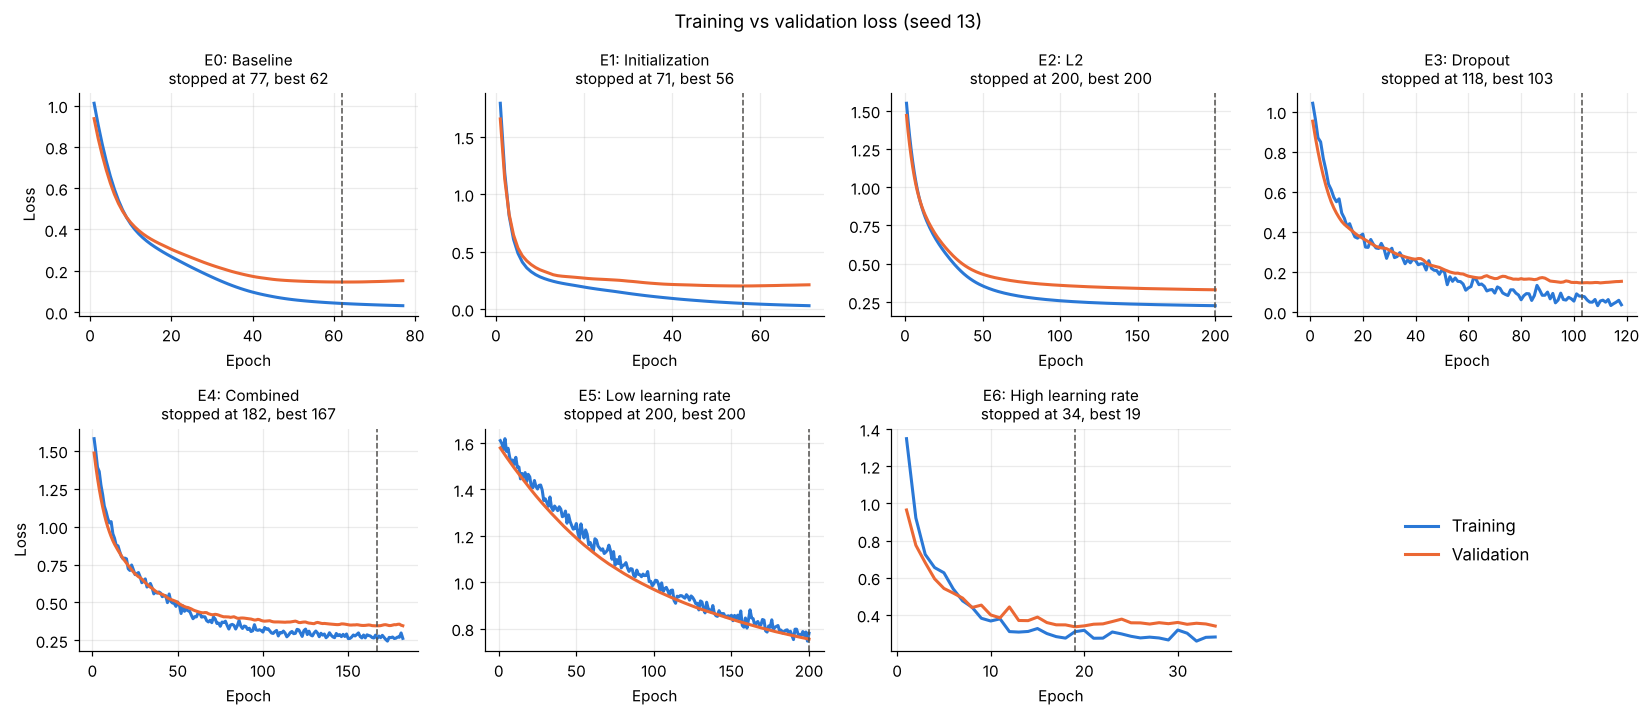

In [12]:
# Eman Amjad | FA23-BAI-013 | Loss curves for every experiment (seed 13)
def curve_grid(key, ylabel, fname, title):
    fig, axes = plt.subplots(2, 4, figsize=(15, 6.6), sharey=(key == "accuracy"))
    for ax, cfg in zip(axes.flat, EXPERIMENTS):
        h = histories[(cfg["exp"], SEEDS[0])]
        e = np.arange(1, len(h[key]) + 1)
        best = int(np.argmin(h["val_loss"])) + 1
        ax.plot(e, h[key], color=C_TRAIN, lw=2, label="Training")
        ax.plot(e, h["val_" + key], color=C_VAL, lw=2, label="Validation")
        ax.axvline(best, color=C_REF, ls="--", lw=1)
        ax.set_title(f"{cfg['exp']}: {cfg['name']}\nstopped at {len(e)}, best {best}", fontsize=10)
        ax.set_xlabel("Epoch")
    axes.flat[-1].axis("off")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    axes.flat[-1].legend(handles, labels, loc="center", frameon=False, fontsize=11)
    axes[0, 0].set_ylabel(ylabel); axes[1, 0].set_ylabel(ylabel)
    fig.suptitle(title, fontsize=12)
    fig.tight_layout()
    fig.savefig(f"{FIG_DIR}/{fname}", dpi=200, bbox_inches="tight")
    plt.show()

curve_grid("loss", "Loss", "fig2_loss_curves.png", "Training vs validation loss (seed 13)")

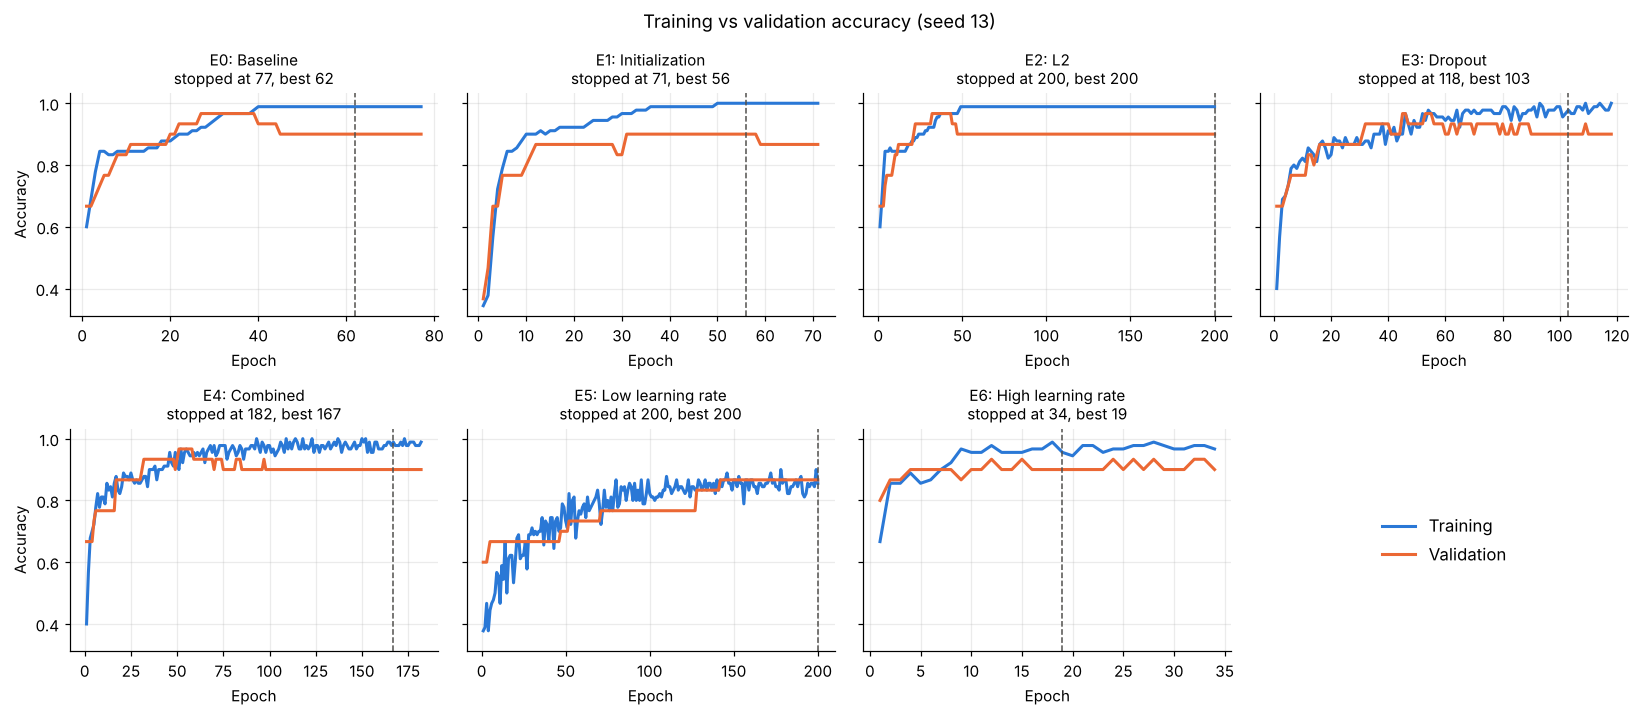

In [13]:
# Eman Amjad | FA23-BAI-013 | Accuracy curves for every experiment (seed 13)
curve_grid("accuracy", "Accuracy", "fig3_accuracy_curves.png", "Training vs validation accuracy (seed 13)")

---

## 8. Metric Comparison

Bars show the mean over the three seeds and the error bars one standard deviation. The dashed line is
the E0 baseline value.

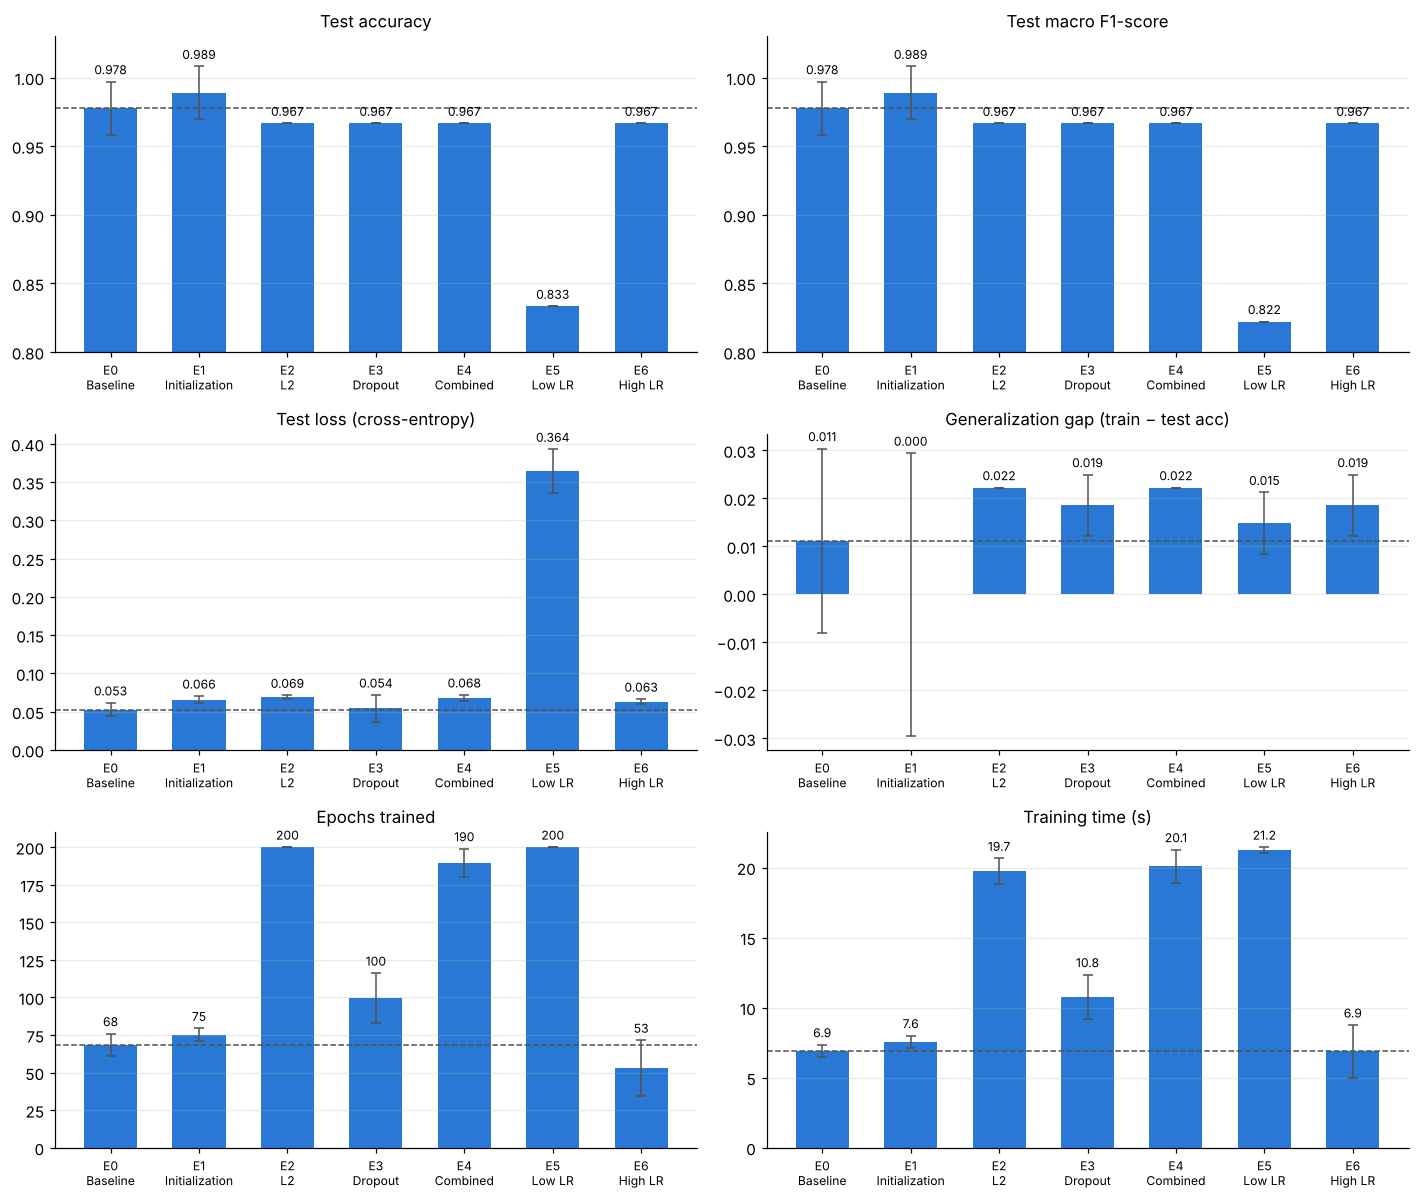

In [14]:
# Eman Amjad | FA23-BAI-013 | Bar charts of the main metrics
panels = [("test_acc", "Test accuracy", "{:.3f}"), ("test_f1_macro", "Test macro F1-score", "{:.3f}"),
          ("test_loss", "Test loss (cross-entropy)", "{:.3f}"),
          ("gen_gap", "Generalization gap (train − test acc)", "{:.3f}"),
          ("epochs_run", "Epochs trained", "{:.0f}"), ("train_time_s", "Training time (s)", "{:.1f}")]
labels = [f"{e}\n{n}".replace(" learning rate", " LR") for e, n in zip(means["exp"], means["name"])]
x = np.arange(len(means))

fig, axes = plt.subplots(3, 2, figsize=(13, 11))
for ax, (col, title, fmt) in zip(axes.flat, panels):
    ax.bar(x, means[col], yerr=stds[col], color=C_BAR, width=0.6,
           error_kw=dict(ecolor=C_REF, capsize=3, lw=1))
    ax.axhline(means.loc[0, col], color=C_REF, ls="--", lw=1)
    for xi, v, s in zip(x, means[col], stds[col]):
        ax.annotate(fmt.format(v), (xi, v + s), ha="center", va="bottom", fontsize=8,
                    xytext=(0, 3), textcoords="offset points")
    ax.set_xticks(x, labels, fontsize=8)
    ax.set_title(title, fontsize=11)
    ax.grid(axis="x", visible=False)
for ax in axes[0, :2]:
    ax.set_ylim(0.8, 1.03)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig4_metric_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

---

## 9. Best Configuration - Confusion Matrix and Classification Report

The configurations are ranked by mean test macro F1, ties broken by the lower mean test loss. The
confusion matrices below sum the predictions of all three seeds (3 × 30 = 90 test predictions).

Ranking by mean test macro F1 (tie-break: lower test loss):


,exp,name,test_acc,test_f1_macro,test_loss,gen_gap,epochs_run,train_time_s
1,E1,Initialization,0.9889,0.9889,0.0657,0.0000,75.3333,7.5766
2,E0,Baseline,0.9778,0.9777,0.0528,0.0111,68.3333,6.9220
3,E3,Dropout,0.9667,0.9666,0.0543,0.0185,99.6667,10.7874
4,E6,High learning rate,0.9667,0.9666,0.0630,0.0185,53.0000,6.8795
5,E4,Combined,0.9667,0.9666,0.0679,0.0222,189.6667,20.1000
6,E2,L2,0.9667,0.9666,0.0688,0.0222,200.0000,19.7244
7,E5,Low learning rate,0.8333,0.8222,0.3644,0.0148,200.0000,21.2467



Best configuration: E1 (Initialization)


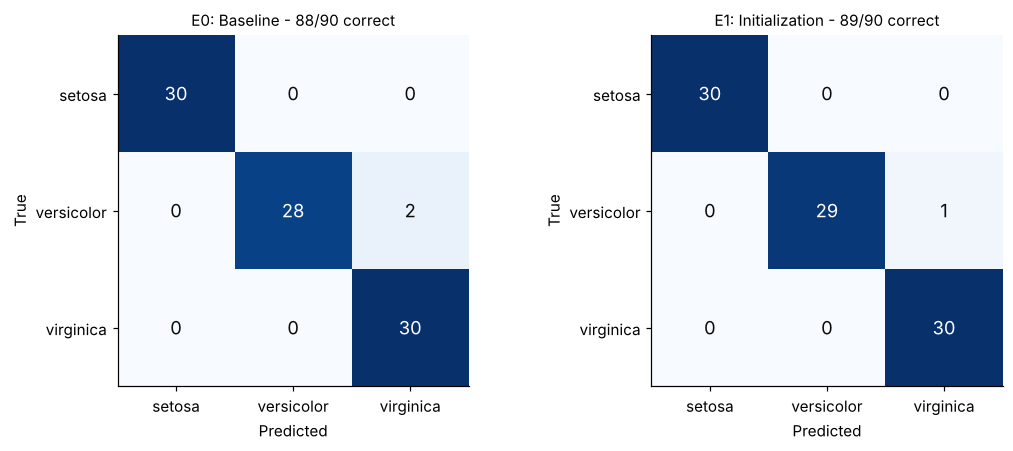

Classification report for E1 (Initialization), all three seeds pooled:

              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        30
  versicolor     1.0000    0.9667    0.9831        30
   virginica     0.9677    1.0000    0.9836        30

    accuracy                         0.9889        90
   macro avg     0.9892    0.9889    0.9889        90
weighted avg     0.9892    0.9889    0.9889        90



In [15]:
# Eman Amjad | FA23-BAI-013 | Ranking and confusion matrices
ranking = means.sort_values(["test_f1_macro", "test_loss"], ascending=[False, True]).reset_index(drop=True)
ranking.index = ranking.index + 1
print("Ranking by mean test macro F1 (tie-break: lower test loss):")
display(ranking[["exp", "name", "test_acc", "test_f1_macro", "test_loss", "gen_gap",
                 "epochs_run", "train_time_s"]].round(4))
BEST = ranking.loc[1, "exp"]
best_name = ranking.loc[1, "name"]
print(f"\nBest configuration: {BEST} ({best_name})")

def pooled_cm(exp):
    yt = np.concatenate([y_test for _ in SEEDS])
    yp = np.concatenate([predictions[(exp, s)] for s in SEEDS])
    return yt, yp, confusion_matrix(yt, yp, labels=[0, 1, 2])

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, exp in zip(axes, ["E0", BEST if BEST != "E0" else "E4"]):
    yt, yp, cm = pooled_cm(exp)
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max())
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=12,
                    color="white" if cm[i, j] > cm.max() / 2 else "#0b0b0b")
    name = means.set_index("exp").loc[exp, "name"]
    ax.set_title(f"{exp}: {name} - {np.trace(cm)}/{cm.sum()} correct", fontsize=10)
    ax.set_xticks(range(3), CLASS_NAMES); ax.set_yticks(range(3), CLASS_NAMES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.grid(False)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig5_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

yt, yp, _ = pooled_cm(BEST)
print(f"Classification report for {BEST} ({best_name}), all three seeds pooled:\n")
print(classification_report(yt, yp, target_names=CLASS_NAMES, digits=4))

In [16]:
# Eman Amjad | FA23-BAI-013 | Save results for the report
def pooled_cms():
    return {e["exp"]: pooled_cm(e["exp"])[2].tolist() for e in EXPERIMENTS}

results = dict(
    student=dict(name="Eman Amjad", roll="FA23-BAI-013"),
    config=dict(split_seed=SPLIT_SEED, seeds=SEEDS, max_epochs=MAX_EPOCHS, patience=PATIENCE,
                batch_size=BATCH_SIZE, n_train=len(y_train), n_val=len(y_val), n_test=len(y_test)),
    versions=dict(tensorflow=tf.__version__, keras=keras.__version__, sklearn=sklearn.__version__),
    experiments=EXPERIMENTS,
    runs=runs.to_dict(orient="records"),
    means=means.to_dict(orient="records"),
    stds=stds.to_dict(orient="records"),
    best=BEST,
    confusion=pooled_cms(),
    demo=dict(best_epoch=best_ep, min_val_loss=float(min(demo_hist["val_loss"])),
              final_val_loss=float(demo_hist["val_loss"][-1]),
              train_loss_at_best=float(demo_hist["loss"][best_ep - 1]),
              final_train_loss=float(demo_hist["loss"][-1]),
              final_train_acc=float(demo_hist["accuracy"][-1]),
              final_val_acc=float(demo_hist["val_accuracy"][-1])),
)
with open("results.json", "w") as f:
    json.dump(results, f, indent=2, default=float)
summary.to_csv("results_summary.csv")
print("Saved: results.json, results_summary.csv, results_per_run.csv and", sorted(os.listdir(FIG_DIR)))

Saved: results.json, results_summary.csv, results_per_run.csv and ['fig1_overfitting_baseline.png', 'fig2_loss_curves.png', 'fig3_accuracy_curves.png', 'fig4_metric_comparison.png', 'fig5_confusion_matrices.png']


---

## 10. Discussion

### 10.1 The overfitting scenario is real, and early stopping catches it

Trained for the full 200 epochs without early stopping (Section 4), the baseline shows the pattern the
lab describes. Validation loss reaches its minimum of **0.145 at epoch 62** and then climbs to
**0.339 by epoch 200**, more than doubling. Over the same epochs training loss keeps falling, from 0.042
to 0.006. Training accuracy reaches 100% while validation accuracy drops from 0.967 (around epoch 30)
to 0.867. The network is not learning new structure after epoch ~60. It is becoming over-confident on
the 90 training samples, and a confident mistake on a validation sample costs a lot of cross-entropy.
With patience 15, early stopping ends this run at epoch 77 and restores the weights of epoch 62, so
the rising part of the curve never reaches the reported model.

### 10.2 Effect of each factor

| Exp. | Change | What happened |
|---|---|---|
| **E1** | He normal instead of Glorot uniform | Highest mean test accuracy / F1 (**0.989**, 89 of 90 pooled test predictions correct), but a *higher* test loss (0.066 vs 0.053) and validation CE (0.188 vs 0.162). The accuracy gain is one test sample in one seed, which is within seed-to-seed noise. He initialization starts the ReLU layers with a larger weight variance, so the loss falls faster in the first ~5 epochs; it does not generalize better here. |
| **E2** | L2 = 0.01 | Test accuracy 0.967 for **every** seed (std 0), test loss 0.069. Training and validation curves stay close and the validation loss never turns upward: all three seeds ran the full 200 epochs. Training took ~2.8× as long as E0 (19.7 s vs 6.9 s). |
| **E3** | Dropout = 0.3 | **Lowest validation cross-entropy of all** (0.153) and a test loss equal to the baseline (0.054). Overfitting is delayed: the best epoch moves from ~53 to ~85, and training takes ~100 epochs instead of ~68. The training curve is noisy because different units are dropped every step. |
| **E4** | L2 0.01 + dropout 0.3 | Same test accuracy as E2 and E3 (0.967, std 0) and a test loss of 0.068. It is the most stable configuration (identical predictions for all seeds), but also the slowest of the early-stopped runs (~190 epochs, 20.1 s). |
| **E5** | LR 0.0001 (vs E4) | **Underfitting, not overfitting.** Train accuracy is only 0.848, test accuracy 0.833, macro F1 0.822 and test loss 0.364, about 5× worse than E4. The loss is still falling steadily at epoch 200, so the model ran out of epoch budget long before converging. Its small generalization gap only reflects that the model is weak on both training and test data. |
| **E6** | LR 0.01 (vs E4) | Same accuracy as E4 (0.967) with a slightly *lower* test loss (0.063 vs 0.068). It converges in ~53 epochs and **6.9 s**, about 3× faster than E4. The curves are noisier and the stopping epoch varies more between seeds (34-71). |

### 10.3 Why the L2 runs almost never stop early

E2, E4 and E5 used nearly all 200 epochs. Keras' `val_loss`, the quantity early stopping monitors,
includes the L2 penalty λ·Σw². As the weights keep shrinking, that penalty keeps falling, so the
monitored value keeps improving slightly even after the cross-entropy has levelled off. The numbers
show this directly: the monitored best validation loss of E4 is 0.345, but its pure validation
cross-entropy is only 0.168, which is about the same as the baseline's 0.162. Roughly half of what
early stopping was watching was the penalty term. The same effect makes Keras' `evaluate()` test loss
(`test_loss_keras`, ≈0.24 for E4) look 3-4× worse than the true test cross-entropy (0.068). This is
why the pure cross-entropy is used for all comparisons in this notebook.

### 10.4 What the ablation shows overall

* **Iris is too easy for accuracy to separate the configurations.** Every configuration except E5
  classifies 29 or 30 of the 30 test samples in every seed, and one sample is worth 3.3 percentage
  points. The differences between E0, E1, E2, E3, E4 and E6 are at most one sample per seed. The
  only errors are versicolor flowers predicted as virginica; setosa is always perfect. Loss values,
  learning curves and seed-to-seed variance are more informative than accuracy here.
* **Early stopping does most of the work.** It already removes the overfitting seen in Section 4, which
  is why the plain baseline is competitive.
* **L2 and dropout change *how* the model trains, not how well it scores.** They keep the training and
  validation curves together and remove the seed-to-seed variance (E2 and E4 have std 0), and
  dropout gives the best validation cross-entropy. On a 90-sample, 4-feature problem they do not
  raise test accuracy, and they cost 1.5-3× more training time.
* **The learning rate has the largest effect of any factor.** At 0.0001 the model underfits badly
  (-13.3 accuracy points vs E4). At 0.01 it matches E4 in a third of the time.
* **Recommended configuration: E6** (Glorot uniform, L2 0.01, dropout 0.3, LR 0.01). It keeps the
  regularization that stops the train/validation curves from diverging, gives the same test accuracy
  as E4 with a lower test loss, and is the fastest to train. E1 has the top accuracy, but the margin
  is one test sample, so it should not be treated as a real improvement.

### 10.5 Limitations

* The validation and test sets have only 30 samples each, so a single flower changes accuracy by 3.3
  points. Validation accuracy is exactly 0.900 for almost every run, which suggests three hard
  versicolor/virginica samples in the validation split.
* Three seeds and one fixed split: the conclusions describe this split. Repeating the study with
  stratified k-fold cross-validation would give tighter error bars.
* The epoch budget (200) and patience (15) are the same for every experiment, as required. This
  penalizes E5, which needs far more epochs to converge at LR 0.0001.

---

## 11. Conclusion

Without early stopping, the baseline MLP overfits Iris: validation loss bottoms out at epoch 62 and then
more than doubles while training loss keeps falling. Early stopping on `val_loss` (patience 15,
restore best weights) prevents this in every experiment. On top of early stopping, L2 regularization
and dropout keep the training and validation curves together and make results identical across
seeds, but they do not improve test accuracy on this small, easy dataset (0.967 vs 0.978 for the
baseline, a difference of one test sample). He-normal initialization makes no meaningful difference.
The learning rate matters most: 0.0001 underfits (test accuracy 0.833), while 0.01 reaches the same
accuracy as the 0.001 setting about 3× faster. The best trade-off between generalization and training
cost is the regularized model with a learning rate of 0.01 (E6).